This code is authored by Raghav Y.
Contains the codes needed to see disparity in the edge and node dataset as well as a visulaizer for ingredient frequency over different cuisines.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path


In [2]:
BASE_DIR = Path.cwd().resolve().parent.parent
DATA_DIR   = BASE_DIR / "common" / "data_processed"
NODES_FILE = DATA_DIR / "nodes_9.0.csv"
EDGES_FILE = DATA_DIR / "edges_6.0.csv"
OUT_DIR = BASE_DIR / "members" / "raghav"



Ingredient: mango
                          Ingredient_Dishes  Total_Dishes  Prevalence (%)
Cuisine                                                                  
Malvani                                 1.0             7           14.29
Uttar Pradesh                           1.0            12            8.33
Gujarati Recipes                        7.0            96            7.29
Coorg                                   1.0            14            7.14
Himachal                                1.0            15            6.67
Kerala Recipes                          8.0           133            6.02
Andhra                                  6.0           109            5.50
Mangalorean                             2.0            45            4.44
Karnataka                               6.0           138            4.35
Indian                                 37.0           927            3.99
Oriya Recipes                           1.0            26            3.85
Sindhi             

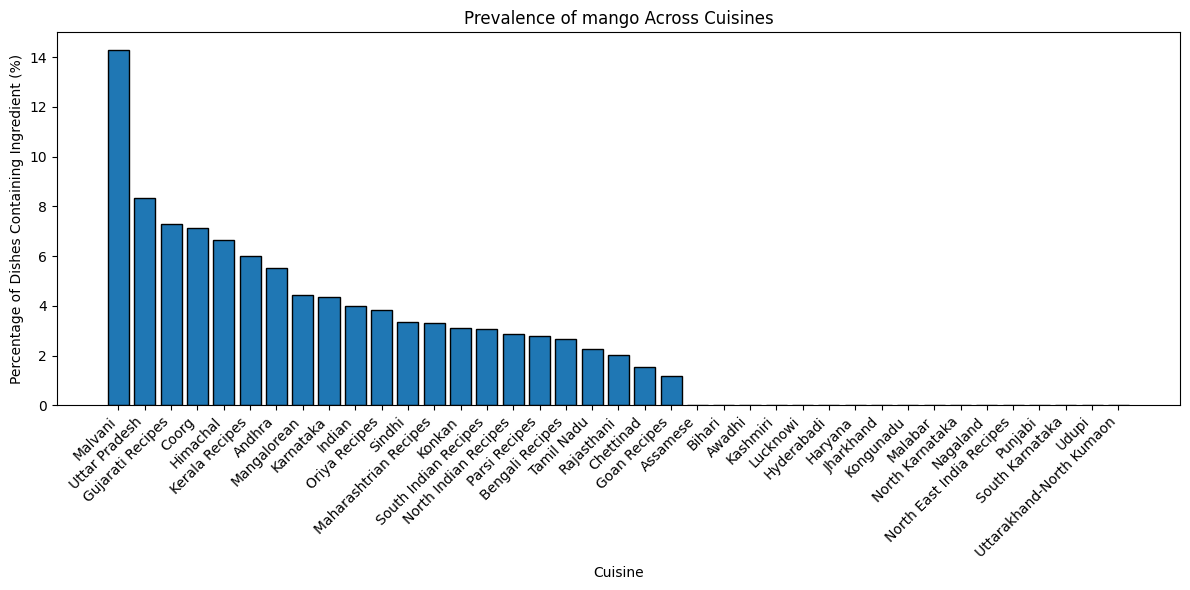

In [3]:
#Load datasets
nodes_df = pd.read_csv(NODES_FILE)
edges_df = pd.read_csv(EDGES_FILE)

#Separate recipes and ingredients
recipes = nodes_df[nodes_df['Type'] == 'Recipe'].copy()
ingredients = nodes_df[nodes_df['Type'] != 'Recipe'].copy()

# Take ingredient input
ingredient_name = input("Enter ingredient name: ").strip().lower()

matching_ingredients = ingredients[
    (ingredients['Label'].astype(str).str.lower() == ingredient_name) |
    (ingredients['Id'].astype(str).str.lower() == ingredient_name)
]

if matching_ingredients.empty:
    print("Ingredient not found!")

else:
    ingredient_ids = set(matching_ingredients['Id'])

    #Find recipes connected to the ingredient
    connected_recipes = set()

    for source, target in edges_df[['Source', 'Target']].itertuples(
        index=False, name=None
    ):
        if source in ingredient_ids:
            connected_recipes.add(target)
        elif target in ingredient_ids:
            connected_recipes.add(source)

    # Retain only recipe IDs
    connected_recipes &= set(recipes['Id'])

    #Total number of dishes in each cuisine
    total_dishes = recipes.groupby('Cuisine')['Id'].nunique()

    #Number of dishes containing ingredient in each cuisine
    ingredient_dishes = recipes[
        recipes['Id'].isin(connected_recipes)
    ]

    ingredient_counts = ingredient_dishes.groupby('Cuisine')['Id'].nunique()

    # Combine and Normalize
    results = pd.DataFrame({
        'Ingredient_Dishes': ingredient_counts,
        'Total_Dishes': total_dishes
    }).fillna(0)

    results['Prevalence (%)'] = (
        results['Ingredient_Dishes'] /
        results['Total_Dishes']
    ) * 100

    results = results.sort_values(
        'Prevalence (%)', ascending=False
    )

    print(f"\nIngredient: {ingredient_name}")
    print(results.round(2).to_string())

    plt.figure(figsize=(12, 6))

    plt.bar(
        results.index.astype(str),
        results['Prevalence (%)'],
        edgecolor='black'
    )

    plt.title(f'Prevalence of {ingredient_name} Across Cuisines')
    plt.xlabel('Cuisine')
    plt.ylabel('Percentage of Dishes Containing Ingredient (%)')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()
